In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt 
import pandas as pd

In [2]:
########## Problem 1

# task 1

# With the hamiltonian and overlap given, there is not that much to this task. Unless I've blundered in the matrix creation itself, this is just applying a scipy function to solve the eigenvalue problem

epsilon_s = -5.34
h = -1.8
s = 0.18

H = [[epsilon_s, h], [h, epsilon_s]]
S = [[1, s], [s, 1]]

E, c = sp.linalg.eigh(H, S)
print("E = ", E, ", c = ", c)

E =  [-6.05084746 -4.31707317] , c =  [[-0.65094455  0.78086881]
 [-0.65094455 -0.78086881]]


In [3]:
# task 2

# It seems that this task has kind of solved itself, because the documentation says that linalg.eigh returns the eigenvalues in ascending order (sorted), and when multiplied out is already the identity
# matrix (normalized). Verifying numerically shows this, since there are 1s along the diagonal and what should be 0s elsewhere. They aren't 0s, but since the 1s are returned as 1.000e+00, I'd venture a
# guess that the 0s being off by 10^(-16) is just machine precision error 

c_transpose = np.transpose(c)

c_t_s_c = c_transpose @ S @ c

print(c_t_s_c)

[[ 1.00000000e+00 -1.30893359e-16]
 [ 1.17879344e-17  1.00000000e+00]]


In [4]:
# task 3

# comparing the energies is easy enough, and I'll just take the percent differences. The differences are so small that we can call them the same. E+ is less than E-, so it is the bonding state and E- 
# is the antibonding state

E_plus = (epsilon_s + h) / (1 + s)
E_minus = (epsilon_s - h) / (1 - s)

print("Percent difference E+:", 100 * np.abs(E_plus - E[0]) / E[0])
print("Percent difference E-:", 100 * np.abs(E_minus - E[1]) / E[1])

Percent difference E+: -1.4678578925016074e-14
Percent difference E-: -2.0573624411132842e-14


In [5]:
# task 4

# When doing the same as task 1 but replacing S with an identity matrix, we can see the energies are slightly different. Subtracting the values shows that E+ gets raised by about 1.1 eV when overlap
# is factored in, and E- gets lowered by about 0.8 eV

H = [[epsilon_s, h], [h, epsilon_s]]
I = [[1, 0], [0, 1]]

E_prime, c_prime = sp.linalg.eigh(H, I)

print(E_prime)

print("E+ shift = ", E_prime[0] - E[0], "eV")
print("E- shift = ", E_prime[1] - E[1], "eV")

[-7.14 -3.54]
E+ shift =  -1.0891525423728803 eV
E- shift =  0.777073170731708 eV


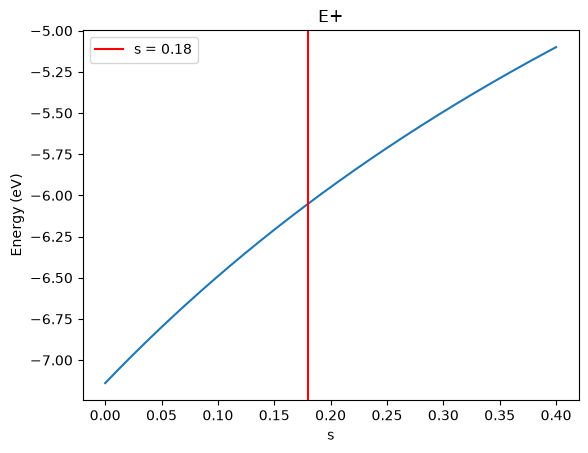

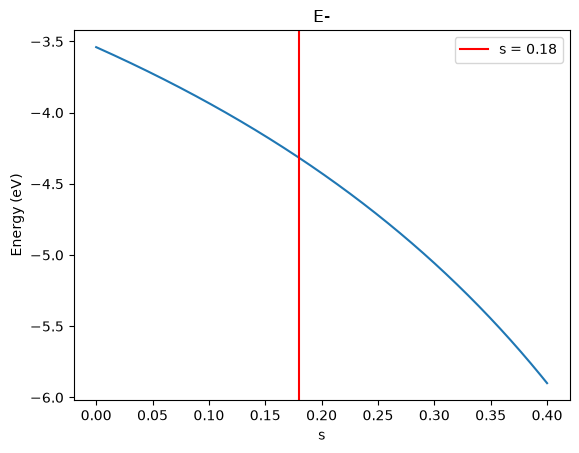

In [6]:
# task 5

# Since task 3 shows that both approaches are basically the same, I'll use equations for plotting instead of eigenvalues. This also seems more straightforward to do since I can just plug the function
# straight into the plot. As for saving the plot, I'll find some way to attach these pngs to my submission

s_sweep = np.linspace(0, 0.4, 1000)

plt.plot(s_sweep, (epsilon_s + h) / (1 + s_sweep))
plt.xlabel("s")
plt.ylabel("Energy (eV)")
plt.title("E+")
plt.axvline(0.18, color = "r", label = "s = 0.18")
plt.legend()
plt.savefig("problem1_task5_graph1.png", dpi = 600)

plt.figure()
plt.plot(s_sweep, (epsilon_s - h) / (1 - s_sweep))
plt.xlabel("s")
plt.ylabel("Energy (eV)")
plt.title("E-")
plt.axvline(0.18, color = "r", label = "s = 0.18")
plt.legend()
plt.savefig("problem1_task5_graph2.png", dpi = 600)

In [7]:
# task 6

# Using an orthogonal basis, the off diagonal terms in the S matrix would be 0. This would reduce the matrix to the identity, becoming a normal eigenvalue problem. Since we are not using an orthogonal
# basis, this is not the case, and we get the generalized eigenvalue problem form Hc = ESc. By using the identity matrix, we are approximating that the impact of overlap is minimal, so we just say
# "there is no overlap" with confidence. 

In [8]:
########## Problem 2

# task 1

# we don't have an overlap matrix for this task, so it's just a regular eigenvalue problem. For the U's, I'll just iterate through using a function. At the end, I append the values to an array, which
# I've only come back to do after starting task 2 and realizing Ill need the values again

epsilon = 0
t = 1
U = [0, 1, 2, 4, 8, 16]
p2_E = []
p2_C = []

def HamiltonianEven(U, epsilon = 0, t = 1):
    return [[2 * epsilon, -2 * t], [-2 * t, 2 * epsilon + U]]

for i in range(len(U)):
    E_inloop, C_inloop = np.linalg.eigh(HamiltonianEven(U[i]))
    print("U/t = ", U[i] / t)
    print("Hamiltonian = ", HamiltonianEven(U[i]))
    print("E = ", E_inloop)
    print("C = ", C_inloop)
    p2_E.append(E_inloop)
    p2_C.append(C_inloop)


U/t =  0.0
Hamiltonian =  [[0, -2], [-2, 0]]
E =  [-2.  2.]
C =  [[-0.70710678 -0.70710678]
 [-0.70710678  0.70710678]]
U/t =  1.0
Hamiltonian =  [[0, -2], [-2, 1]]
E =  [-1.56155281  2.56155281]
C =  [[-0.78820544 -0.61541221]
 [-0.61541221  0.78820544]]
U/t =  2.0
Hamiltonian =  [[0, -2], [-2, 2]]
E =  [-1.23606798  3.23606798]
C =  [[-0.85065081 -0.52573111]
 [-0.52573111  0.85065081]]
U/t =  4.0
Hamiltonian =  [[0, -2], [-2, 4]]
E =  [-0.82842712  4.82842712]
C =  [[-0.92387953 -0.38268343]
 [-0.38268343  0.92387953]]
U/t =  8.0
Hamiltonian =  [[0, -2], [-2, 8]]
E =  [-0.47213595  8.47213595]
C =  [[-0.97324899 -0.22975292]
 [-0.22975292  0.97324899]]
U/t =  16.0
Hamiltonian =  [[0, -2], [-2, 16]]
E =  [-0.24621125 16.24621125]
C =  [[-0.99250756 -0.12218326]
 [-0.12218326  0.99250756]]


In [9]:
# task 2

# Since I have prepared the eigenvalues and vectors ahead of time in the last task, I can just iterate with the needed calculations. E_(GS)/t is unitless since t = 1 is given as an energy unit. Since the
# basis is {covalent, ionic}, the ionic probability will be related to the 2nd component of the ground state eigenvector. For this reason, I use c[i][1][0] equivalent to c[which U Im looking at][2nd value]
# [first vector]. J/t is unitless for the same reason as E_(GS). 

E_T = 2 * epsilon

for i in range(len(U)):
    print("U/t = ", U[i] / t)
    print("E_(GS) / t = ", p2_E[i][0] / t)
    print("Ionic probability = ", p2_C[i][1][0]**2)
    print("J/t = ", (E_T - p2_E[i][0]) / t)

U/t =  0.0
E_(GS) / t =  -2.0
Ionic probability =  0.4999999999999999
J/t =  2.0
U/t =  1.0
E_(GS) / t =  -1.5615528128088303
Ionic probability =  0.37873218748183357
J/t =  1.5615528128088303
U/t =  2.0
E_(GS) / t =  -1.2360679774997896
Ionic probability =  0.2763932022500209
J/t =  1.2360679774997896
U/t =  4.0
E_(GS) / t =  -0.8284271247461902
Ionic probability =  0.14644660940672624
J/t =  0.8284271247461902
U/t =  8.0
E_(GS) / t =  -0.4721359549995794
Ionic probability =  0.052786404500042045
J/t =  0.4721359549995794
U/t =  16.0
E_(GS) / t =  -0.24621125123532106
Ionic probability =  0.014928749927334053
J/t =  0.24621125123532106


In [10]:
# task 3

# I'll just make a function with the given equation and iterate through it. Percent differences between the values found here and the last task seem to be identical +- machine precision

def E_groundstate(U, epsilon, t):
    return 2 * epsilon + 0.5 * U - np.sqrt(4 * t**2 + (U**2) / 4)

for i in range(len(U)):
    print("U/t = ", U[i] / t)
    print("E_(GS) numerically = ", E_groundstate(U[i], epsilon, t))
    print("Percent difference = ", 100 * np.abs(E_groundstate(U[i], epsilon, t) - (p2_E[i][0] / t)) / E_groundstate(U[i], epsilon, t))

U/t =  0.0
E_(GS) numerically =  -2.0
Percent difference =  -0.0
U/t =  1.0
E_(GS) numerically =  -1.5615528128088303
Percent difference =  -0.0
U/t =  2.0
E_(GS) numerically =  -1.2360679774997898
Percent difference =  -1.7963785889362148e-14
U/t =  4.0
E_(GS) numerically =  -0.8284271247461903
Percent difference =  -1.3401577416544655e-14
U/t =  8.0
E_(GS) numerically =  -0.4721359549995796
Percent difference =  -4.702980202497584e-14
U/t =  16.0
E_(GS) numerically =  -0.24621125123532117
Percent difference =  -4.50922944851143e-14


In [11]:
# task 4

# Ill just iterate through U like the other problems but exclude U = 0, and pull the J values from the saved matrices. Looking at these values, as U increases, the estimate approaches the exact J,
# which is exactly what the limit comment on this problem is talking about. In terms of units here, J doesn't have t to cancel out the units, but there is also no physical unit specified, so I went
# with just "energy units"

for i in range(len(U)):
    if i == 0:
        continue
    print("U/t = ", U[i] / t)
    print("Exact J = ", E_T - p2_E[i][0], "energy units")
    print("Large U superexchange estimate = ", 4 * t**2 / U[i], "energy units")

U/t =  1.0
Exact J =  1.5615528128088303 energy units
Large U superexchange estimate =  4.0 energy units
U/t =  2.0
Exact J =  1.2360679774997896 energy units
Large U superexchange estimate =  2.0 energy units
U/t =  4.0
Exact J =  0.8284271247461902 energy units
Large U superexchange estimate =  1.0 energy units
U/t =  8.0
Exact J =  0.4721359549995794 energy units
Large U superexchange estimate =  0.5 energy units
U/t =  16.0
Exact J =  0.24621125123532106 energy units
Large U superexchange estimate =  0.25 energy units


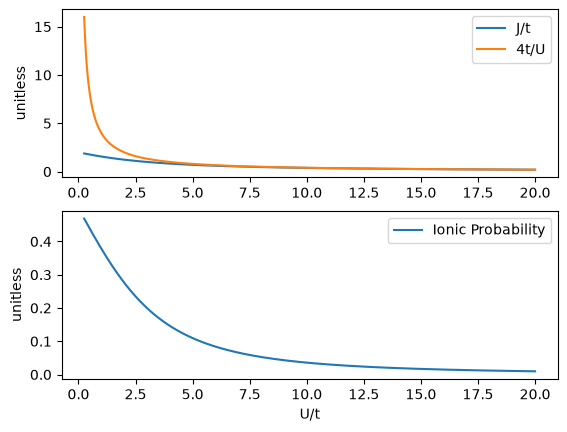

In [12]:
# task 5

# I'll sweep U from 0.25 to 20, and find J using the groundstate function I made in task 3 since we know it's accurate. I also made the estimate into a function, and even though I could
# manually remove the t, since it's a plot of J/t, I imagine it would be most reasonable to plot (4t^2/U)/t. For the ionic probability, I just sweep the U through the hamiltonian and append
# the probabilities to an array for plotting. Both of the y labels are unitless, sice the top graph is energy/energy and the bottom graph is a probability.

U_sweep = np.linspace(0.25, 20, 1000)

def J_function(U, epsilon, t):
    return 2 * epsilon - E_groundstate(U, epsilon, t)

def SE_estimate(U, t):
    return 4 * t**2 / U

ionic_prob = []

for i in range(len(U_sweep)):
    E_inloop, C_inloop = np.linalg.eigh(HamiltonianEven(U_sweep[i]))
    ionic_prob.append(C_inloop[1][0]**2)

fig, ax = plt.subplots(2, 1)
ax[0].plot(U_sweep, J_function(U_sweep, epsilon, t) / t, label = "J/t")
ax[0].plot(U_sweep, SE_estimate(U_sweep, t) / t, label = "4t/U")
ax[0].set_ylabel("unitless")
ax[0].legend()
ax[1].plot(U_sweep, ionic_prob, label = "Ionic Probability")
ax[1].set_ylabel("unitless")
ax[1].set_xlabel("U/t")
ax[1].legend()
plt.savefig("problem2_task5_graph.png", dpi = 600)

In [13]:
# task 6

# As U/t increases, the ionic probability goes down, meaning double occupancy is less favored and the electrons are more localized. Looking at the graph from task 5, the superexchange
# expression starts to be quantitatively useful around U/t = 5, when it starts to match up with J/t pretty nicely. 

In [14]:
########## Problem 3

# task 1

# This task is just setting up the R vector and then doing some simple calculations with it. I did also define hbar^2 /m_e here since I'll need it later anyway.

R = [3.2, 2.3, 2.6]

h2m = 7.62

bond_length = np.sqrt(R[0]**2 + R[1]**2 + R[2]**2)
l = R[0] / bond_length
m = R[1] / bond_length
n = R[2] / bond_length

print("Bond length:", bond_length, "Angstroms")
print("l =", l, ", m =", m, ", n =", n)
print("Sum of direction cosine squares = ", l**2 + m**2 + n**2)

Bond length: 4.72122865364515 Angstroms
l = 0.6777896676386039 , m = 0.48716132361524656 , n = 0.5507041049563657
Sum of direction cosine squares =  1.0


In [15]:
# task 2

# Since we are given the equations for the potenials, we can calculate them pretty easily. The h2m is eV angstroms^2, so dividing by bond length^2 returns just eV

Vsss = -1.32 * h2m / bond_length**2
Vsps = 1.42 * h2m / bond_length**2
Vpps = 2.22 * h2m / bond_length**2
Vppp = -0.63 * h2m / bond_length**2

print("Vsss:", Vsss, "eV")
print("Vsps:", Vsps, "eV")
print("Vpps:", Vpps, "eV")
print("Vppp:", Vppp, "eV")

Vsss: -0.4512516823687753 eV
Vsps: 0.48543741588156125 eV
Vpps: 0.7589232839838495 eV
Vppp: -0.21537012113055184 eV


In [16]:
# task 3

# Ideally, I don't want to place each element into the matrix manually. It's made of a 1x1, 1x3, 3x1, and 3x3 matrix, and Ill try to automate it to my best ability. 

R_unit = [l, m, n]
R_unit_transpose = np.transpose(R_unit)
I = np.identity(3)
RRT = np.outer(R_unit, R_unit)

H_12 = np.zeros((4, 4))

for i in range(4):
    for j in range(4):
        if i == j == 0:
            H_12[i][j] = Vsss
        if i == 0 and not j == 0:
            H_12[i][j] = Vsps * R_unit_transpose[j - 1]
        if j == 0 and not i == 0:
            H_12[i][j] = -Vsps * R_unit[i - 1]
        if not i == 0 and not j == 0:
            H_12[i][j] = Vppp * I[i-1, j-1] + (Vpps - Vppp) * RRT[i-1, j-1]

# to add the labels, I added the pandas package on top of the recommended packages. 

labels_x = ["|s>", "|p_x>", "|p_y>", "|p_z>"]
labels_y = ["<s|", "<p_x|", "<p_y|", "<p_z|"]

H_12_table = pd.DataFrame(H_12, columns = labels_y, index = labels_x)

print(H_12_table)

            <s|     <p_x|     <p_y|     <p_z|
|s>   -0.451252  0.329024  0.236486  0.267332
|p_x> -0.329024  0.232219  0.321705  0.363666
|p_y> -0.236486  0.321705  0.015855  0.261385
|p_z> -0.267332  0.363666  0.261385  0.080109


In [17]:
# task 4

# After reversing the R vector, I can reuse a lot of the task 3 code.

R_unit_rev = [-l, -m, -n]
R_unit_transpose_rev = np.transpose(R_unit_rev)
I = np.identity(3)
RRT_rev = np.outer(R_unit_rev, R_unit_rev)

H_12_rev = np.zeros((4, 4))

for i in range(4):
    for j in range(4):
        if i == j == 0:
            H_12_rev[i][j] = Vsss
        if i == 0 and not j == 0:
            H_12_rev[i][j] = Vsps * R_unit_transpose_rev[j - 1]
        if j == 0 and not i == 0:
            H_12_rev[i][j] = -Vsps * R_unit_rev[i - 1]
        if not i == 0 and not j == 0:
            H_12_rev[i][j] = Vppp * I[i-1, j-1] + (Vpps - Vppp) * RRT_rev[i-1, j-1]

# to verify that making R negative is equivalent to the transpose, I can just make a matrix taking the differences of each element. Since the difference matrix returns 0 in
# every element, that means they were indeed the same matrix

H_12_difference = np.zeros((4,4))
H_12_transpose = np.transpose(H_12)

for i in range(4):
    for j in range(4):
        H_12_difference[i][j] = H_12_transpose[i][j] - H_12_rev[i][j]

print(H_12_difference)

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


Sign of <s| |p_x> changes
Sign of <s| |p_y> changes
Sign of <s| |p_z> changes
Sign of <p_x| |s> changes
Sign of <p_y| |s> changes
Sign of <p_z| |s> changes


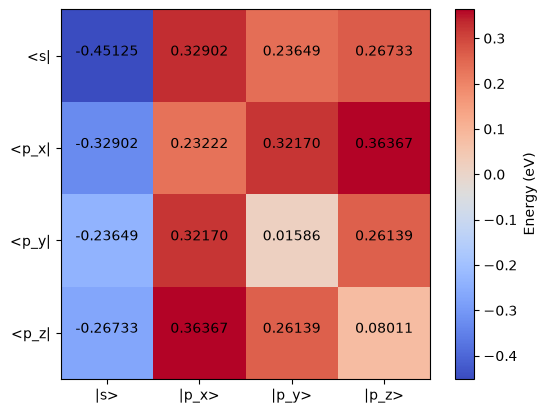

In [18]:
# task 5

# Listing which signs change can be done by just checking if the difference between H_12 and the reverse is 0 or not. 

sign_rev = np.empty((4, 4))

for i in range(4):
    for j in range(4):
        if not H_12_rev[i][j] - H_12[i][j] == 0:
            print("Sign of", labels_y[i], labels_x[j], "changes")

# For the heat map, I can use matplot's imshow on the matrix, and then just align the axis with my labels from before. Since the colors don't really flow into
# each other to make a nice gradient, I'll just add the numbers into the matrix as well. I do cut them off so they fit in the boxes. 

fig, ax = plt.subplots()
heat_map = ax.imshow(H_12, cmap = "coolwarm")
ax.set_xticks(range(4))
ax.set_yticks(range(4))
ax.set_xticklabels(labels_x)
ax.set_yticklabels(labels_y)
plt.colorbar(heat_map, label = "Energy (eV)")
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{H_12[i,j]:.5f}", ha = "center")
plt.savefig("problem3_task5_heatmap.png", dpi = 600)

In [19]:
# task 6

# As we looked at in class, for the p elements, when they are reversed along their respective axes, their bond is still the same. So if it was +- meeting +-, then -+ meet. If you
# swap them, you still the -+ meeting. However, when meeting s + and p +-, then you get ++ in the middle. Reversing their order for p +- and s + now has -+ in the middle. This text
# descriptions has been a disaster, but I think it kind of makes sense.

In [20]:
########## Problem 4

# task 1

# This task asks to make an 8x8 matrix for "several separations" so I'll make a function for the matrix and then put in whatever separations may be useful. Constructing the matrix itself
# only needs 2 4x4 matrices, since H11 and H22 are the same and H12 and H21 are transposes of each other. The H11 and H22 matrices are filled with 0 outside of the diagonals which have 
# eps_s for the ss bond and eps_p for the pp bond. For H12 and H21, since we're given that we use the z axis, the only nonzero off diagonal terms are going to be between s and p_z.

eps_s = -34.02
eps_p = -16.77

def matrix8x8(bond_length, eps_s, eps_p):
    Vsss = -1.32 * h2m / bond_length**2
    Vsps = 1.42 * h2m / bond_length**2
    Vpps = 2.22 * h2m / bond_length**2
    Vppp = -0.63 * h2m / bond_length**2

    H_same = np.zeros((4, 4))
    H_different = np.zeros((4, 4))

    for i in range(4):
        for j in range(4):
            if i == j:
                if i == 0:
                    H_same[i][j] = eps_s
                else:
                    H_same[i][j] = eps_p

    for i in range(4):
        for j in range(4):
            if i == 0:
                if j == 0:
                    H_different[i][j] = Vsss
                if j == 3:
                    H_different[i][j] = Vsps
            if i == 3:
                if j == 0:
                    H_different[i][j] = -Vsps
                if j == 3: 
                    H_different[i][j] = Vpps
            if i in (1, 2):
                if i == j:
                    H_different[i][j] = Vppp
        
    H_full = np.block([[H_same, H_different],[np.transpose(H_different), H_same]])
    return H_full

# Verifying hermiticity can be done by subtracting the transpose of the matrix from itself and seeing if you get 0s. Really, it should be the complex transpose, but there are no imaginary
# values in these particular matrices, so I won't worry about that. For example, I will use a separation distance of 5 angstroms. Since the matrix returned all 0s, this means the matrix
# is hermitian. 

print("Sep distance 5 angstroms:")
print(matrix8x8(5, eps_s, eps_p))
print(matrix8x8(5, eps_s, eps_p) - np.transpose(matrix8x8(5, eps_s, eps_p)))

# We still need to diagonalize the matrix and classify the eigenstates. Since sigma bonds have cylindrical symmetry, those will be with elements s1 s2 p_z1 and p_z2, and pi bonds will be 
# with elements p_x1 p_x2 p_y1 and p_y2. I can check which is dominant in the vector and then classify that vector as being a certain state. 

E_full, C_full = np.linalg.eigh(matrix8x8(5, eps_s, eps_p))

s_states = []
p_states = []

for i in range(len(C_full)):
    sum_sigma = C_full[0][i]**2 + C_full[3][i]**2 + C_full[4][i]**2 + C_full[7][i]**2
    sum_pi = C_full[1][i]**2 + C_full[2][i]**2 + C_full[5][i]**2 + C_full[6][i]**2
    if sum_sigma > sum_pi:
        s_states.append(i)
    else: 
        p_states.append(i)

# now I will check the associated energy to see if the states are bonding or antibonding. The lower energies will be bonding and higher will be antibonding. In the pi bonds, the bonding
# states are the ones with the energy roughly -16.96 eV and in the sigma bonds, the bonding states are the ones with energy roughly -34.43 eV and -17.44 eV.

print("Sigma")
for i in range(len(s_states)):
    print(E_full[s_states[i]])

print("Pi")
for i in range(len(p_states)):
    print(E_full[p_states[i]])

Sep distance 5 angstroms:
[[-34.02       0.         0.         0.        -0.402336   0.
    0.         0.432816]
 [  0.       -16.77       0.         0.         0.        -0.192024
    0.         0.      ]
 [  0.         0.       -16.77       0.         0.         0.
   -0.192024   0.      ]
 [  0.         0.         0.       -16.77      -0.432816   0.
    0.         0.676656]
 [ -0.402336   0.         0.        -0.432816 -34.02       0.
    0.         0.      ]
 [  0.        -0.192024   0.         0.         0.       -16.77
    0.         0.      ]
 [  0.         0.        -0.192024   0.         0.         0.
  -16.77       0.      ]
 [  0.432816   0.         0.         0.676656   0.         0.
    0.       -16.77    ]]
[[0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]]
Sigma
-34.43336401612167
-33.6283471853907
-17.43562

In [21]:
# task 2 

# I am unable to make a nice diagram like we see in class, so I will make some ascii art instead

#   -16.08 eV             |___________|
#   -16.58 eV   |_____^_____|       |_____^_____|
#   -16.96 eV   |___^___v___|       |___^___v___|
#   -17.44 eV             |___^___v___|
#
#   -33.63 eV             |___^___v___|
#   -34.43 eV             |___^___v___|

# As can be seen, the only unoccupied state is antibonding sigma pz (highest), and the pi px and pi py antibonding states each have one electron. All the other states are filled. For
# the bond order, this means 8 electrons are in bonding states (2 in -34.43, 2 in -17.44, 2 in each -16.96) and 4 electrons in antibonding (2 in -33.63 and 1 in each -16.58), which 
# means the bond order is (8 - 4)/2 = 2.

In [22]:
# task 3

# I start by making functions for E_band using the occupancy of each orbital times its energy depending on the distance. We don't have this distance, but we can continue to the calibrating
# phase. Since E_total is E_band + C/d^4, we can find the derivative to be dE_band - 4C/d^5. We set this equal to 0, rearrange for C, use finite differences to get dE_band, and plug in d_0. 
# Now with calibrated C found, I make functions for V_rep and E_total. 

def E_band(d):
    E, C = np.linalg.eigh(matrix8x8(d, eps_s, eps_p))
    return 2*E[0] + 2*E[1] + 2*E[2] + 2*E[3] + 2*E[4] + E[5] + E[6]

d_0 = 1.208
delta = 10**(-10)

dE_band = (E_band(d_0 + delta) - E_band(d_0 - delta)) / (2 * delta)
calibrated_C = d_0**5 * dE_band / 4

print("Calibrated C =", calibrated_C)

def V_rep(d):
    return calibrated_C / (d**4)

def E_total(d):
    return E_band(d) + V_rep(d)

Calibrated C = 39.672965970549974


Equilibrium distance = 1.2080208020802081 angstroms
Equilibrium energy = 15.6739597757159 eV


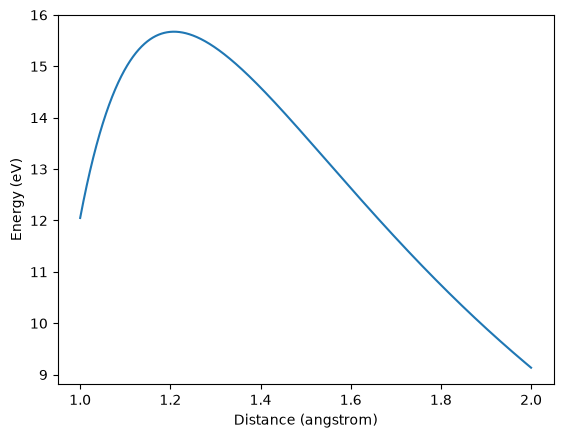

In [23]:
# task 4

# To find the cohesive energy, I sweep around d_0 to find the max value since that is what the calibrated C was for. Where the max is, I take that point and put it into the equation for
# cohesive energy using E_total at that distance and E_sep given in the problem. 

E_sep = 2 * (2 * eps_s + 4 * eps_p)

d_eq = np.linspace(1, 2, 10000)

grid = []

for i in range(len(d_eq)):
    grid.append(E_sep - E_total(d_eq[i]))

plt.plot(d_eq, grid)
plt.xlabel("Distance (angstrom)")
plt.ylabel("Energy (eV)")

d_eq_index = np.argmax(grid)

print("Equilibrium distance =", d_eq[d_eq_index], "angstroms")
print("Equilibrium energy =", E_sep - E_total(d_eq[d_eq_index]), "eV")

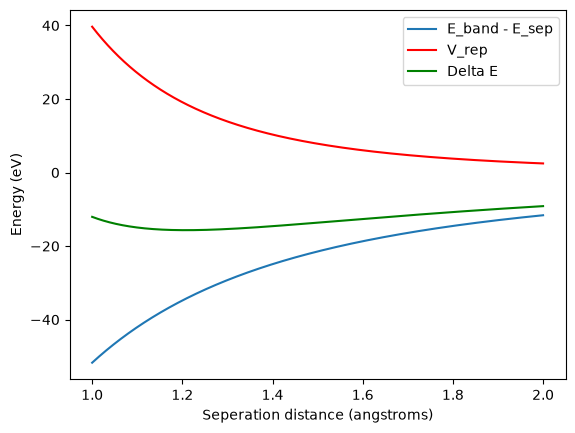

In [24]:
# task 5

# I reused the d_eq linspace made in the last one to plug into the needed functions for this task. Then they are graphed together

E_band_minus_E_sep = []
V_rep_d = []
delE = []

for i in range(len(d_eq)):
    E_band_minus_E_sep.append(E_band(d_eq[i]) - E_sep)
    V_rep_d.append(V_rep(d_eq[i]))
    delE.append(E_total(d_eq[i]) - E_sep)

plt.plot(d_eq, E_band_minus_E_sep, label = "E_band - E_sep")
plt.plot(d_eq, V_rep_d, label = "V_rep", color = "r")
plt.plot(d_eq, delE, label = "Delta E", color = "g")
plt.xlabel("Seperation distance (angstroms)")
plt.ylabel("Energy (eV)")
plt.legend()
plt.savefig("problem4_task5_graph.png", dpi = 600)

In [25]:
# task 6

# The textbook says that paramagnetism is associated with unpaired electrons and diamagnetism is when all electrons are paired. Going back to task 2, there are 2 unpaired electrons, 
# which means that O2 will be paramagnetic. 

In [26]:
# task 7 

# having looked up the various properties of O2, the bond order and magnetism are predicted by this model correctly. The bond length is in the ballpark, but the number I'm seeing for
# real O2 is 1.21 angstroms compared to the found 1.208 here, but I'd say those are close enough. The cohesive energy is the major discrepency here, as I found it to be about 15.7 eV
# but experimental numbers find 2.6 eV per atom, so 5.2 eV for O2. The first limiation that comes to mind is that without experimental data, or even with poor experimental data, I don't
# think this model will work because the calibration part will be poor. I think the other limitation would be that it ignores interactions between electrons since the model starts with
# assuming electrons are localized, and then intersite interactions are a perturbation.